This page is a Jupyter notebook, `docs/guide/notebooks.ipynb`. smalldocs reads the cells of the notebook and the outputs that were saved in it. It does not start a kernel, which is the program that runs the code. So the page shows what the notebook showed when it last ran.

## Text and printed output

In [1]:
words = "smalldocs reads the outputs a notebook was saved with".split()
for w in words[:4]:
    print(w.upper())

SMALLDOCS
READS
THE
OUTPUTS


## Rich output

An output can hold the same result in several formats. smalldocs shows the first format that it can show, in this order:

1. HTML
2. SVG, PNG and JPEG pictures
3. Markdown, LaTeX and plain text

smalldocs shows a Markdown output as Markdown:

In [2]:
from IPython.display import Markdown
Markdown("**Bold** Markdown, from a cell's output")

**Bold** Markdown, from a cell's output

An HTML output goes into the page unchanged, for example a table from pandas. The option `#| echo: false` hides the code of the next cell:

In [3]:
#| echo: false
# This cell's code is hidden by `#| echo: false`; only its output shows.
show_table()

Page,Kind
index.qmd,Markdown with additions
notes.md,Markdown
this.ipynb,Notebook


The page keeps a picture from an output. The next cell gives the picture a caption with `#| fig-cap`, and an alt text for a screen reader with `#| fig-alt`:

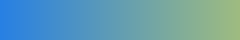

In [4]:
#| fig-cap: A gradient, from a picture that the notebook saved.
#| fig-alt: A band of colour that goes from blue at the left to green at the right.
gradient()  # a picture, saved in the notebook as a PNG

## Errors

An error shows its traceback. smalldocs removes the colour codes of the terminal from it:

In [5]:
1 / 0

ZeroDivisionError: division by zero

## Cell options

A code cell can start with option lines that begin with `#|`. These options hide parts of a cell:

- `#| echo: false` hides the code.
- `#| output: false` hides the output.
- `#| include: false` hides the code and the output.

A cell can also have tags, labels in its metadata that Jupyter lets you set. The tags `remove-cell`, `remove-input` and `remove-output` hide the same parts.

The options `echo`, `output` and `include` of the page apply to each cell too. So `echo: false` in the front matter hides the code of every cell. The `#|` line of a cell wins over the page.

### Figures and tables

These options give a caption to the outputs of a cell, and set where the outputs go:

| Option | What it does | Default |
|---|---|---|
| `fig-cap` | The caption of the picture. A list gives one caption to each picture of the cell, in order | None |
| `fig-alt` | The alt text of the picture, which a screen reader reads | None |
| `fig-align` | `left`, `right` or `center`: where the picture goes, as for the [figures of a page](markdown.qmd#figures) | `center`, for a picture with a caption or an alt text |
| `tbl-cap` | The caption of the table in an HTML output, such as a table from pandas | None |
| `column`, `fig-column`, `tbl-column` | The column of the outputs, such as `margin`, `page` or `screen`. These are the [classes for the margin and wide content](markdown.qmd#the-margin-and-wide-content), without `.column-`. The code stays in the column of the text | The column of the text |
| `layout-ncol`, `layout-nrow` | The number of columns or rows for the outputs of the cell | One output under the other |

For example, this cell makes two pictures. They go side by side, each with its own caption:

```python
#| fig-cap: ["Sales", "Costs"]
#| layout-ncol: 2
plot_sales()
plot_costs()
```

### Folded code and line numbers

These options change how the code of a cell shows:

| Option | What it does | Default |
|---|---|---|
| `code-fold` | `true` hides the code under a line that opens it when you click it. `show` does the same, but the code starts open | `false` |
| `code-summary` | The words on the line of folded code | `Code` |
| `code-line-numbers` | `true` puts a number before each line of the code | `false` |
| `code-overflow` | `wrap` wraps a long line onto the next line. `scroll` scrolls it to the side | `scroll` |

The next cell sets `#| code-fold: true` and `#| code-summary: Show the code`:

In [6]:
#| code-fold: true
#| code-summary: Show the code
print(sum(range(1, 11)))

55


Only the `#|` lines of a cell set these options for the cell. The options of the page do not apply to the code cells of a notebook, except `echo`, `output` and `include`. So `code-fold: true` in the front matter, or `code-line-numbers: true` in `_smalldocs.yml`, changes no cell of a notebook.

A cell that sets none of these options renders as it did before smalldocs 0.3.0. Its code shows in full, and its outputs go one under the other, with no caption.